# EUR/USD variance risk premium: continuous premium or event risk?

Sells one-month EUR/USD implied vol (EVZ) whenever the VRP is above its sample mean and books IV at entry minus realised vol over the next 21 trading days. Then tests whether Fed and ECB meetings inside the holding window change the P&L, using Newey-West errors because the daily-entry trades overlap. Full write-up in `report/FX_VRP_Report.pdf`.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns
import scipy.stats as stats
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant

## 1. Data: EUR/USD spot and EVZ from Yahoo Finance, 2018–2024

In [12]:
# Log returns: time-additive and consistent with how IV is quoted.
data = yf.download("EURUSD=X", start="2018-01-01", end="2024-12-31")

spot = data["Close"]

log_returns = np.log(spot / spot.shift(1))
log_returns = log_returns.dropna()
# 21-day window matches one-month straddle horizon; sqrt(252) annualises to IV scale.
realized_vol = log_returns.rolling(window=21).std() * np.sqrt(252)

# EVZ quoted in percentage points, /100 to match RV decimal scale.
implied_vol = yf.download("^EVZ", start="2018-01-01", end="2024-12-31")["Close"]
implied_vol = implied_vol / 100


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [13]:
realized_vol = realized_vol.squeeze()
implied_vol = implied_vol.squeeze()

df = pd.DataFrame({
    "realized_vol": realized_vol,
    "implied_vol": implied_vol
}).dropna()

print(df.head())

            realized_vol  implied_vol
Date                                 
2018-01-30      0.077105       0.0809
2018-01-31      0.077079       0.0879
2018-02-01      0.076461       0.0829
2018-02-02      0.076074       0.0870
2018-02-05      0.078981       0.0881


## 2. The premium: VRP = IV − RV

In [14]:
# VRP = IV - RV. Positive mean (~0.008) confirms the structural premium.
df["VRP"] = df["implied_vol"] - df["realized_vol"]
print(df["VRP"].describe())


count    1740.000000
mean        0.008082
std         0.015667
min        -0.062362
25%        -0.000632
50%         0.007165
75%         0.016001
max         0.123843
Name: VRP, dtype: float64


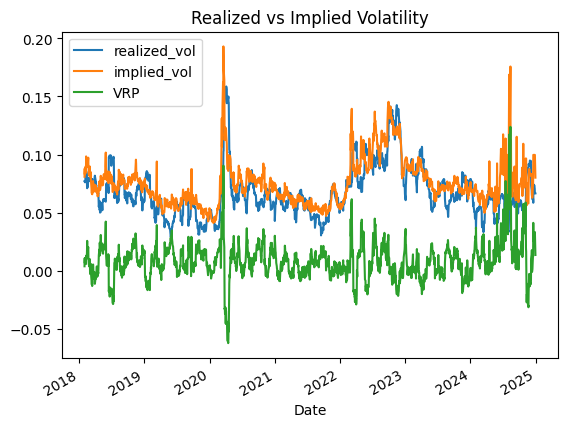

In [15]:
plot = df[["realized_vol", "implied_vol", "VRP"]].plot(title="Realized vs Implied Volatility")

## 3. Base strategy

        date       pnl
0 2018-01-31  0.004248
1 2018-02-02  0.008006
2 2018-02-05  0.008766
3 2018-02-08  0.019818
4 2018-02-09  0.016982
Mean P&L per trade: 0.0092
820
Sharpe Ratio: 0.4340
5% VaR: -0.0198
5% CVaR: -0.0433


<Axes: >

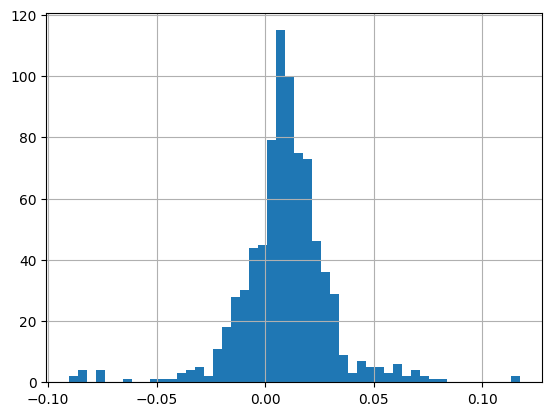

In [16]:
# Entry: VRP above mean signals an above-average mispricing to capture.
# Full-sample mean introduces look-ahead bias (noted as a limitation).
threshold = df["VRP"].mean()

# shift(-21) aligns RV with the 21-day holding period post-entry.
future_rv = df["realized_vol"].shift(-21)
results = []

for i in range(len(df)):
    if df["VRP"].iloc[i] > threshold:
        # P&L = IV sold at entry - RV realised over holding period.
        pnl = df["implied_vol"].iloc[i]  - future_rv.iloc[i]
        results.append({"date": df.index[i], "pnl": pnl})

trades = pd.DataFrame(results)
print(trades.head())
print(f"Mean P&L per trade: {trades['pnl'].mean():.4f}")
        
print(len(trades)) 

# Per-trade Sharpe; annualised later via sqrt(252/21).
sharpe_ratio = trades["pnl"].mean() / trades["pnl"].std() 
print(f"Sharpe Ratio: {sharpe_ratio:.4f}")     

VaR = trades["pnl"].quantile(0.05)
print(f"5% VaR: {VaR:.4f}")

# CVaR preferred here: fat tails (kurtosis 8.24) make VaR understate tail risk.
Cvar = trades[trades["pnl"] <= VaR]["pnl"].mean()
print(f"5% CVaR: {Cvar:.4f}")


trades["pnl"].hist(bins=50)


## 4. Fed meetings inside the holding window

Mean P&L for trades near Fed meetings: 0.0053
Mean P&L for trades not near Fed meetings: 0.0188
Percentage of trades near Fed meetings: 70.98%


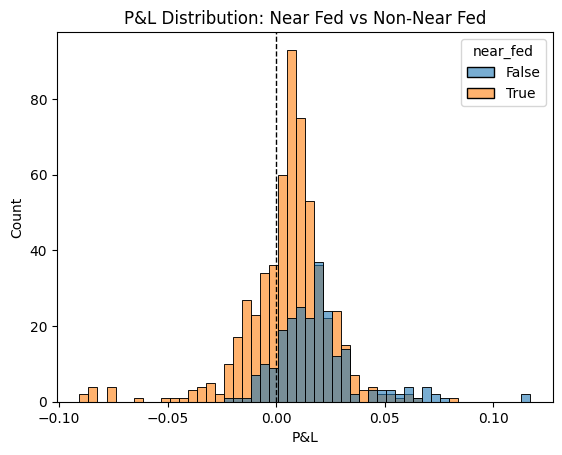

In [17]:
fed_dates = [
    # 2018
    "2018-01-31", "2018-03-21", "2018-05-02", "2018-06-13",
    "2018-08-01", "2018-09-26", "2018-11-08", "2018-12-19",
    # 2019
    "2019-01-30", "2019-03-20", "2019-05-01", "2019-06-19",
    "2019-07-31", "2019-09-18", "2019-10-30", "2019-12-11",
    # 2020
    "2020-01-29", "2020-03-03", "2020-03-15", "2020-04-29",
    "2020-06-10", "2020-07-29", "2020-09-16", "2020-11-05", "2020-12-16",
    # 2021
    "2021-01-27", "2021-03-17", "2021-04-28", "2021-06-16",
    "2021-07-28", "2021-09-22", "2021-11-03", "2021-12-15",
    # 2022
    "2022-01-26", "2022-03-16", "2022-05-04", "2022-06-15",
    "2022-07-27", "2022-09-21", "2022-11-02", "2022-12-14",
    # 2023
    "2023-02-01", "2023-03-22", "2023-05-03", "2023-06-14",
    "2023-07-26", "2023-09-20", "2023-11-01", "2023-12-13",
    # 2024
    "2024-01-31", "2024-03-20", "2024-05-01", "2024-06-12",
    "2024-07-31", "2024-09-18", "2024-11-07", "2024-12-18",
]

fed_dates = pd.to_datetime(fed_dates)  

# Forward window only: pre-entry events are already priced into IV.
def near_fed_meeting(trade_date):
    end_date = trade_date + pd.Timedelta(days=30)
    return any((fed_dates >= trade_date) & (fed_dates <= end_date))

trades["near_fed"] = trades["date"].apply(near_fed_meeting)

mean_pnl_near_fed = trades[trades["near_fed"] == True]["pnl"].mean()
print(f"Mean P&L for trades near Fed meetings: {mean_pnl_near_fed:.4f}")

mean_pnl__not_near_fed = trades[trades["near_fed"] == False]["pnl"].mean()
print(f"Mean P&L for trades not near Fed meetings: {mean_pnl__not_near_fed:.4f}")

x = len(trades[trades["near_fed"] == True]["pnl"])

near_fed = (x / len(trades)) * 100
print(f"Percentage of trades near Fed meetings: {near_fed:.2f}%")

sns.histplot(data=trades, x="pnl", hue="near_fed", bins=50, alpha=0.6)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("P&L Distribution: Near Fed vs Non-Near Fed")
plt.xlabel("P&L")
plt.show()


In [18]:
# equal_var=False -> Welch's t-test: handles unequal variances between groups.
# Still assumes independence, which overlapping 21-day windows violate.
a = trades[trades["near_fed"] == True]["pnl"]
b = trades[trades["near_fed"] == False]["pnl"]
a =  a.dropna()
b =  b.dropna()

result = stats.ttest_ind(a, b, equal_var=False)
print(f"T-statistic: {result.statistic:.4f}")
print(f"P-value: {result.pvalue:.4f}")


T-statistic: -8.6900
P-value: 0.0000


In [19]:
# Newey-West HAC corrects for autocorrelation from overlapping windows.
# t-stat collapses from -8.69 to -3.72, still significant at 1%.
trades_clean = trades.dropna(subset=["pnl"])

# Binary regression: coefficient on near_fed = mean P&L difference between groups.
X = add_constant(trades_clean["near_fed"].astype(int))
y = trades_clean["pnl"]
model = OLS(y, X).fit()

# maxlags=21 matches holding-period overlap; beyond 21 days windows don't overlap.
nw_result = model.get_robustcov_results(cov_type='HAC', use_t=True, maxlags=21)
print(nw_result.summary())


                            OLS Regression Results                            
Dep. Variable:                    pnl   R-squared:                       0.084
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     13.85
Date:                Tue, 14 Apr 2026   Prob (F-statistic):           0.000212
Time:                        17:53:47   Log-Likelihood:                 2003.8
No. Observations:                 807   AIC:                            -4004.
Df Residuals:                     805   BIC:                            -3994.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0188      0.003      5.970      0.0

## 5. ECB meetings inside the holding window

Mean P&L for trades near ECB meetings: 0.0084
Mean P&L for trades not near ECB meetings: 0.0107
Percentage of trades near ECB meetings: 65.61%


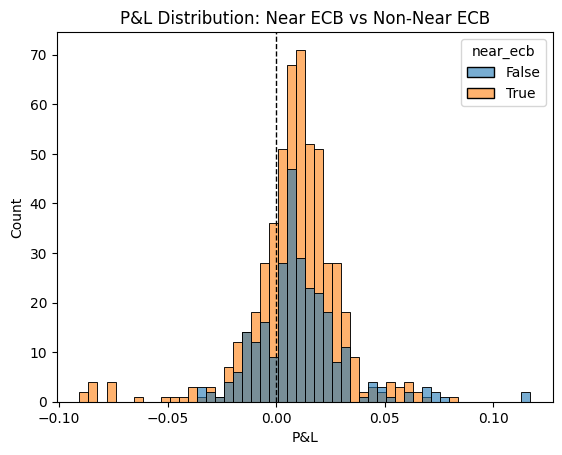

In [20]:
# ECB analysis: USD dominance in EUR/USD vol suggests smaller effect than Fed.
ecb_dates = [
    # 2018
    "2018-01-25", "2018-03-08", "2018-04-26", "2018-06-14",
    "2018-07-26", "2018-09-13", "2018-10-25", "2018-12-13",
    # 2019
    "2019-01-24", "2019-03-07", "2019-04-10", "2019-06-06",
    "2019-07-25", "2019-09-12", "2019-10-24", "2019-12-12",
    # 2020
    "2020-01-23", "2020-03-12", "2020-04-30", "2020-06-04",
    "2020-07-16", "2020-09-10", "2020-10-29", "2020-12-10",
    # 2021
    "2021-01-21", "2021-03-11", "2021-04-22", "2021-06-10",
    "2021-07-22", "2021-09-09", "2021-10-28", "2021-12-16",
    # 2022
    "2022-02-03", "2022-03-10", "2022-04-14", "2022-06-09",
    "2022-07-21", "2022-09-08", "2022-10-27", "2022-12-15",
    # 2023
    "2023-02-02", "2023-03-16", "2023-05-04", "2023-06-15",
    "2023-07-27", "2023-09-14", "2023-10-26", "2023-12-14",
    # 2024
    "2024-01-25", "2024-03-07", "2024-04-11", "2024-06-06",
    "2024-07-18", "2024-09-12", "2024-10-17", "2024-12-12",
]

ecb_dates = pd.to_datetime(ecb_dates)
def near_ecb_meeting(trade_date):
    end_date = trade_date + pd.Timedelta(days=30)
    return any((ecb_dates >= trade_date) & (ecb_dates <= end_date))

trades["near_ecb"] = trades["date"].apply(near_ecb_meeting)
mean_pnl_near_ecb = trades[trades["near_ecb"] == True]["pnl"].mean()
print(f"Mean P&L for trades near ECB meetings: {mean_pnl_near_ecb:.4f}")

mean_pnl_not_near_ecb = trades[trades["near_ecb"] == False]["pnl"].mean()
print(f"Mean P&L for trades not near ECB meetings: {mean_pnl_not_near_ecb:.4f}")   

x_ecb = len(trades[trades["near_ecb"] == True]["pnl"])
near_ecb = (x_ecb / len(trades)) * 100
print(f"Percentage of trades near ECB meetings: {near_ecb:.2f}%")

sns.histplot(data=trades, x="pnl", hue="near_ecb", bins=50, alpha=0.6)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("P&L Distribution: Near ECB vs Non-Near ECB")
plt.xlabel("P&L")
plt.show()


In [ ]:
trades_clean_ecb = trades.dropna(subset=["pnl"])
c_ecb = trades_clean_ecb[trades_clean_ecb["near_ecb"] == True]["pnl"]
d_ecb = trades_clean_ecb[trades_clean_ecb["near_ecb"] == False]["pnl"]

result_ecb = stats.ttest_ind(c_ecb, d_ecb, equal_var=False)
print(f"T-statistic: {result_ecb.statistic:.4f}")
print(f"P-value: {result_ecb.pvalue:.4f}")


X_ecb = add_constant(trades_clean_ecb["near_ecb"].astype(int)) 
y_ecb = trades_clean_ecb["pnl"]
model_ecb = OLS(y_ecb, X_ecb).fit()
# p = 0.523: cannot reject null. ECB not significant enough to dictate EUR/USD vol
nw_result_ecb = model_ecb.get_robustcov_results(cov_type='HAC', use_t=True, maxlags=21)
print(nw_result_ecb.summary()) 

print(len(df))
print(len(trades))


T-statistic: -1.4844
P-value: 0.1383
                            OLS Regression Results                            
Dep. Variable:                    pnl   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                    0.4085
Date:                Tue, 14 Apr 2026   Prob (F-statistic):              0.523
Time:                        17:53:47   Log-Likelihood:                 1969.4
No. Observations:                 807   AIC:                            -3935.
Df Residuals:                     805   BIC:                            -3925.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          

## 6. Volatility regime

In [22]:
trades["implied_vol"] = trades["date"].map(df["implied_vol"])

# Median over mean: robust to COVID spike skewing the threshold.
median_IV = trades["implied_vol"].median()

# IV (forward-looking) used to define regime since it reflects current premium on offer.
def vol_regime(row):
    if row["implied_vol"] > median_IV:
        return True
    else:
        return False
    
trades["high_vol_regime"] = trades.apply(vol_regime, axis=1)
mean_pnl_high_vol = trades[trades["high_vol_regime"] == True]["pnl"].mean()
print(f"Mean P&L for trades in high volatility regime: {mean_pnl_high_vol:.4f}")

# VRP is countercyclical: fear = larger premium for the seller.
mean_pnl_low_vol = trades[trades["high_vol_regime"] == False]["pnl"].mean()
print(f"Mean P&L for trades in low volatility regime: {mean_pnl_low_vol:.4f}")


Mean P&L for trades in high volatility regime: 0.0136
Mean P&L for trades in low volatility regime: 0.0049


                            OLS Regression Results                            
Dep. Variable:                    pnl   R-squared:                       0.043
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     5.672
Date:                Tue, 14 Apr 2026   Prob (F-statistic):             0.0175
Time:                        17:53:48   Log-Likelihood:                 1986.0
No. Observations:                 807   AIC:                            -3968.
Df Residuals:                     805   BIC:                            -3959.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0049      0.003     

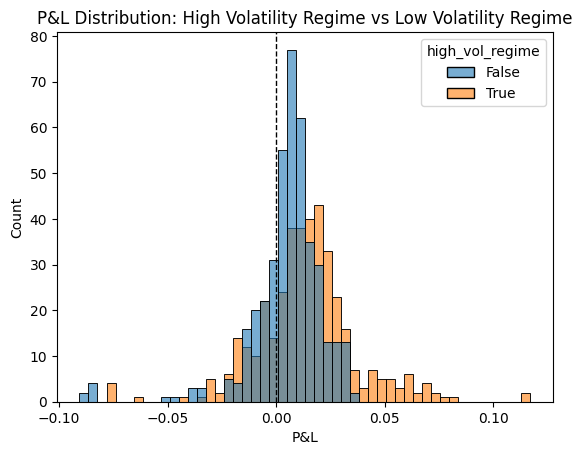

In [23]:
sns.histplot(data=trades, x="pnl", hue="high_vol_regime", bins=50, alpha=0.6)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("P&L Distribution: High Volatility Regime vs Low Volatility Regime")
plt.xlabel("P&L")

trades_clean_vol = trades.dropna(subset=["pnl"])
x_vol = add_constant(trades_clean_vol["high_vol_regime"].astype(int))
y_vol = trades_clean_vol["pnl"]
model_vol = OLS(y_vol, x_vol).fit()
# p = 0.017: significant at 5% but weaker than Fed finding due to tail losses in high-vol regime.
nw_result_vol = model_vol.get_robustcov_results(cov_type='HAC', use_t=True, maxlags=21)
print(nw_result_vol.summary())


## 7. Year-by-year

In [24]:
trades["year"] = pd.DatetimeIndex(trades["date"]).year
annual_pnl = trades.groupby("year")["pnl"].agg(["mean", "count", "std"])
annual_pnl["sharpe"] = annual_pnl["mean"] / annual_pnl["std"]
print(annual_pnl)

          mean  count       std    sharpe
year                                     
2018  0.006592    116  0.013229  0.498287
2019  0.011675    128  0.010503  1.111585
2020  0.002864    141  0.031110  0.092051
2021  0.003993     83  0.010802  0.369606
2022  0.005302     98  0.019599  0.270546
2023  0.006877     81  0.009752  0.705176
2024  0.020799    160  0.025411  0.818505


## 8. Strategy comparison

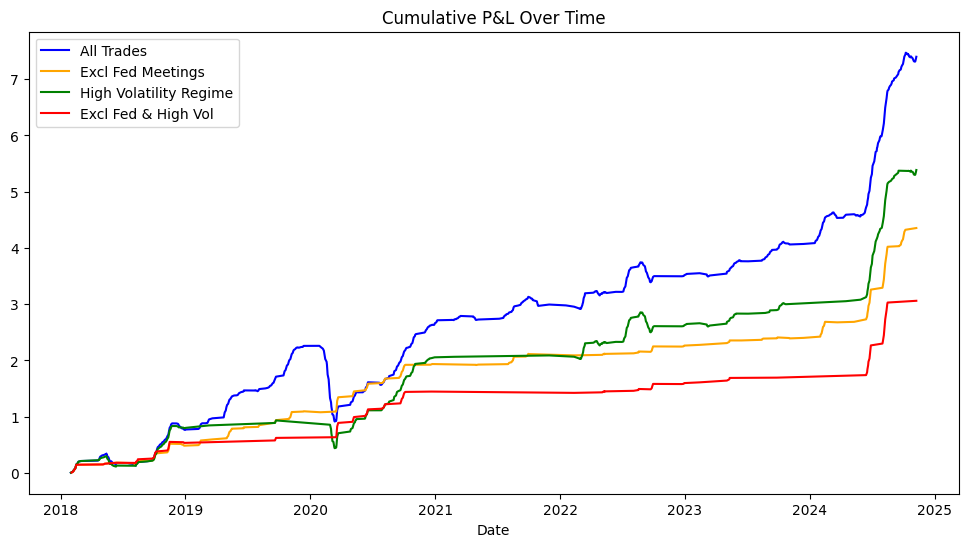

In [26]:
# ECB filter excluded: insignificant signal would cut trades without improving returns.
base = trades.copy()

excl_fed = trades[trades["near_fed"] == False]

high_vol = trades[trades["high_vol_regime"] == True]

excl_fed_high_vol = trades[(trades["near_fed"] == False) & (trades["high_vol_regime"] == True)]

# Sort by date so cumsum reflects chronological equity curve.
base_pnl_sum = base.sort_values("date")["pnl"].cumsum()
excl_fed_pnl_sum = excl_fed.sort_values("date")["pnl"].cumsum()
high_vol_pnl_sum = high_vol.sort_values("date")["pnl"].cumsum()
excl_fed_high_vol_pnl_sum = excl_fed_high_vol.sort_values("date")["pnl"].cumsum()

plt.figure(figsize=(12, 6))
plt.plot(base["date"], base_pnl_sum, label="All Trades", color="blue") 
plt.plot(excl_fed["date"], excl_fed_pnl_sum, label="Excl Fed Meetings", color="orange")
plt.plot(high_vol["date"], high_vol_pnl_sum, label="High Volatility Regime", color="green")
plt.plot(excl_fed_high_vol["date"], excl_fed_high_vol_pnl_sum, label="Excl Fed & High Vol", color="red")
plt.title("Cumulative P&L Over Time")
plt.xlabel("Date")
plt.legend()
plt.show()


In [ ]:
# sqrt(252/21) annualises per-trade Sharpe to industry-standard scale.
sharpe_base = (base["pnl"].mean() / base["pnl"].std())*np.sqrt(252/21)
sharpe_excl_fed = (excl_fed["pnl"].mean() / excl_fed["pnl"].std())*np.sqrt(252/21)
sharpe_high_vol = (high_vol["pnl"].mean() / high_vol["pnl"].std())*np.sqrt(252/21)
sharpe_excl_fed_high_vol = (excl_fed_high_vol["pnl"].mean() / excl_fed_high_vol["pnl"].std())*np.sqrt(252/21)
Var_base = base["pnl"].quantile(0.05)
Var_excl_fed = excl_fed["pnl"].quantile(0.05)
Var_high_vol = high_vol["pnl"].quantile(0.05)
Var_excl_fed_high_vol = excl_fed_high_vol["pnl"].quantile(0.05)

# CVaR is the key comparison: Fed filter cuts tail loss by 74%.
Cvar_base = base[base["pnl"] <= Var_base]["pnl"].mean()
Cvar_excl_fed = excl_fed[excl_fed["pnl"] <= Var_excl_fed]["pnl"].mean()
Cvar_high_vol = high_vol[high_vol["pnl"] <= Var_high_vol]["pnl"].mean()
Cvar_excl_fed_high_vol = excl_fed_high_vol[excl_fed_high_vol["pnl"] <= Var_excl_fed_high_vol]["pnl"].mean()


summary = pd.DataFrame({
    "Strategy": ["Base", "Excl Fed", "High Vol", "Excl Fed & High Vol"],
    "Trades": [len(base), len(excl_fed), len(high_vol), len(excl_fed_high_vol)],
    "Mean PnL": [base["pnl"].mean(), excl_fed["pnl"].mean(), high_vol["pnl"].mean(), excl_fed_high_vol["pnl"].mean()],
    "Sharpe": [sharpe_base, sharpe_excl_fed, sharpe_high_vol, sharpe_excl_fed_high_vol],
    "Conditional VaR": [Cvar_base, Cvar_excl_fed, Cvar_high_vol, Cvar_excl_fed_high_vol]
})

print(summary.to_string(index=False))



           Strategy  Trades  Mean PnL   Sharpe  Conditional VaR
               Base     820  0.009168 1.503455        -0.043316
           Excl Fed     238  0.018849 3.278451        -0.011126
           High Vol     406  0.013634 1.982552        -0.039464
Excl Fed & High Vol     132  0.024485 3.641202        -0.008442
